<a href="https://colab.research.google.com/github/Anushka924403/learning_preprocessing/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'loan_data (1).csv', 'sample_data']


In [ ]:
import pandas as pd
df=pd.read_csv('/content/loan_data (1).csv')
print(df)

       person_age person_gender person_education  person_income  \
0            22.0        female           Master        71948.0   
1            21.0        female      High School        12282.0   
2            25.0        female      High School        12438.0   
3            23.0        female         Bachelor        79753.0   
4            24.0          male           Master        66135.0   
...           ...           ...              ...            ...   
44995        27.0          male        Associate        47971.0   
44996        37.0        female        Associate        65800.0   
44997        33.0          male        Associate        56942.0   
44998        29.0          male         Bachelor        33164.0   
44999        24.0          male      High School        51609.0   

       person_emp_exp person_home_ownership  loan_amnt        loan_intent  \
0                   0                  RENT    35000.0           PERSONAL   
1                   0                   O

In [ ]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

x= (45000, 13)
y= (45000,)
Numerical Columns: ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']
Categorical Columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
training data= (31500, 13)
testing data= (13500, 13)
loan_status
0    35000
1    10000
Name: count, dtype: int64

Target Distribution (%):
loan_status
0    77.777778
1    22.222222
Name: proportion, dtype: float64


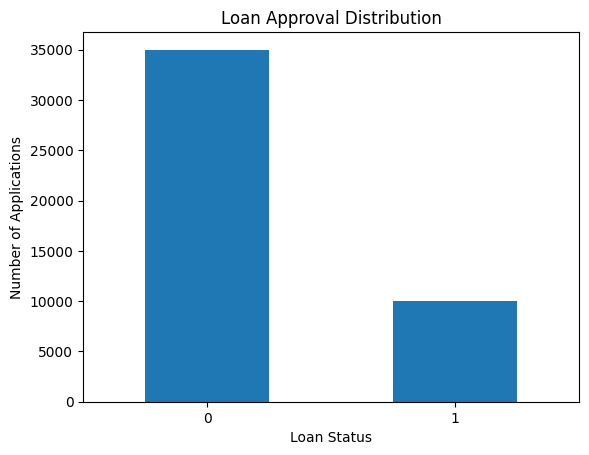

In [ ]:
#Separate Features (X) and Target (y)
X = df.drop('loan_status', axis=1)
y = df['loan_status']
#X contains all input columns except loan_status.
#y contains only loan_status
print("x=",X.shape)
print("y=",y.shape)

#Identify Numerical and Categorical Columns
#We have both numerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns
print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
print("training data=",X_train.shape)
print("testing data=",X_test.shape)

# Count the occurrences of each target class
print(df['loan_status'].value_counts())

# Calculate percentage distribution
print("\nTarget Distribution (%):")
print(df['loan_status'].value_counts(normalize=True) * 100)

# Visualize target distribution
df['loan_status'].value_counts().plot(
    kind='bar',
    title='Loan Approval Distribution'
)

plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#FEATURE SCALING AND ENCODING
#We need to scale numerical columns and encode categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)
print("prepro=",preprocessor)
#StandardScaler() scales numerical features.
#OneHotEncoder() converts categorical values into numerical representations.
#ColumnTransformer() applies the appropriate transformation to each group of columns

#CREATE LOGISTIC REGRESSION MODEL
#Now import and create our model
model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])
print("model=",model)
# preprocessing performs scaling and encoding.
#classifier contains our Logistic Regression algorithm.
#max_iter=1000 allows up to 1,000 optimization iterations.
#We use a pipeline so that preprocessing is learned only from training data and then consistently applied to testing data

#TRAIN THE MODEL-here actual training was start
model.fit(X_train, y_train)

#make prediction
y_pred = model.predict(X_test)

print(y_pred[:20])#check prediction

#calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("Accuracy:", accuracy * 100, "%")#print in percentage



prepro= ColumnTransformer(transformers=[('num', StandardScaler(),
                                 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score'],
      dtype='object')),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='object'))])
model= Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score'],
      dtype='object')),
                                                 ('cat',
                          

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='object'))])),
                ('classifier', LogisticRegression(max_iter=1000))])